In [1]:
from astropy.io import fits
from astropy.table import Table

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [50]:
model = 'gaussian'
r0 = '13'

entries = {
    "sigE_0": "gstools_finite_sigE0_" + model + "_r" +r0 + "_N256_bin0",
    "sigE_1": "gstools_finite_sigE1_" + model + "_r" +r0 + "_N256_bin0",
    "sigE_2": "gstools_finite_sigE2_" + model + "_r" +r0 + "_N256_bin0",
}

In [51]:
data = {}

for alias, name in entries.items():

    with fits.open(name + ".fits") as hdul:

        data[alias] = {
            "name": name,
            "sb": hdul[1].data.copy(),
            "vv": hdul[2].data.copy(),
            "hdr": hdul[0].header.copy(),
        }

In [52]:
data['sigE_0']['vv']

array([[ 0.71403819,  0.74766551,  0.77391824, ...,  0.22259099,
         0.17795637,  0.12644929],
       [ 0.74018587,  0.77314962,  0.79830391, ...,  0.23305512,
         0.186735  ,  0.13366784],
       [ 0.76147567,  0.79348848,  0.81732605, ...,  0.23961929,
         0.19174515,  0.13732052],
       ...,
       [-0.37119039, -0.34574765, -0.3158021 , ..., -0.50966189,
        -0.4779202 , -0.44031142],
       [-0.3866858 , -0.35909117, -0.32674153, ..., -0.49814897,
        -0.46412709, -0.4244062 ],
       [-0.39941196, -0.36945833, -0.33453768, ..., -0.48274425,
        -0.4465574 , -0.40491288]], dtype='>f8')

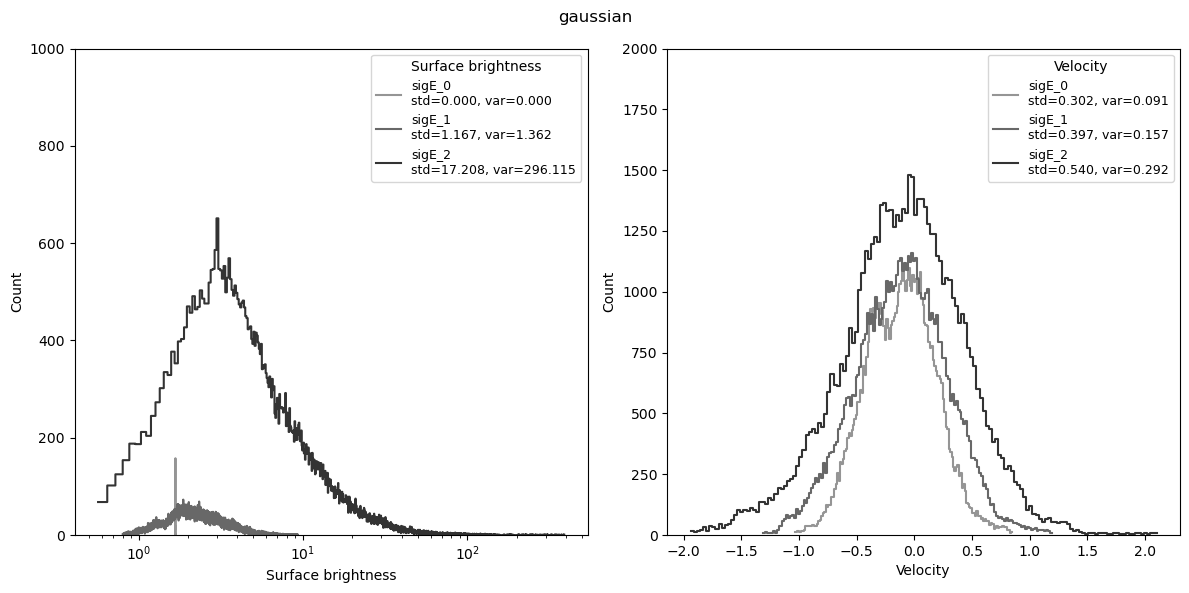

In [53]:
# ---------------------------------------------------------
# Grayscale palette
# ---------------------------------------------------------

n_samples = len(data)

colors = sns.color_palette(
    "Greys",
    n_colors=n_samples + 2,
)[2:]


# ---------------------------------------------------------
# Figure
# ---------------------------------------------------------

fig, (ax, axx) = plt.subplots(
    1,
    2,
    sharey=False,
    figsize=(12, 6),
)


# ---------------------------------------------------------
# Histograms
# ---------------------------------------------------------

for (alias, entry), color in zip(data.items(), colors):

    # Flatten arrays
    sb = entry["sb"].ravel()
    vv = entry["vv"].ravel()

    # Convert FITS big-endian arrays to native byte order
    sb = np.asarray(sb, dtype=np.float64)
    vv = np.asarray(vv, dtype=np.float64)

    # -----------------------------------------------------
    # Statistics
    # -----------------------------------------------------

    sb_std = sb.std()
    sb_var = sb.var()

    vv_std = vv.std()
    vv_var = vv.var()

    # Labels for legends
    sb_label = (
        f"{alias}\n"
        f"std={sb_std:.3f}, var={sb_var:.3f}"
    )

    vv_label = (
        f"{alias}\n"
        f"std={vv_std:.3f}, var={vv_var:.3f}"
    )


    # -----------------------------------------------------
    # Surface brightness
    # -----------------------------------------------------

    sns.histplot(
        x=sb,
        bins=5000,
        element="step",
        fill=False,
        color=color,
        label=sb_label,
        ax=ax,
    )


    # -----------------------------------------------------
    # Velocity
    # -----------------------------------------------------

    sns.histplot(
        x=vv,
        bins=150,
        element="step",
        fill=False,
        color=color,
        label=vv_label,
        ax=axx,
    )


# ---------------------------------------------------------
# Y limits
# ---------------------------------------------------------

ax.set_ylim(0, 1000)
axx.set_ylim(0, 2000)


# ---------------------------------------------------------
# Axis scales
# ---------------------------------------------------------

ax.set_xscale("log")
# ax.set_yscale("log")


# ---------------------------------------------------------
# Labels
# ---------------------------------------------------------

ax.set_xlabel("Surface brightness")
ax.set_ylabel("Count")

axx.set_xlabel("Velocity")
axx.set_ylabel("Count")


# ---------------------------------------------------------
# Legends
# ---------------------------------------------------------

ax.legend(
    title="Surface brightness",
    fontsize=9,
)

axx.legend(
    title="Velocity",
    fontsize=9,
)


# ---------------------------------------------------------
# Figure title
# ---------------------------------------------------------

fig.suptitle(model)

plt.tight_layout()


# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

fig.savefig(
    "pdf_" + model + ".jpg",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [54]:
for i in data:
    print(len(data[i]["vv"]))

256
256
256


In [55]:
for i in data:
    print(data[i]["vv"].std())

0.3023141718226243
0.3965998029360351
0.5404714573874104


In [56]:
for i in data:
    print(data[i]["vv"].var())

0.09139385848479922
0.15729140368890185
0.2921093962504714


In [57]:
for i in data:
    print(len(data[i]["sb"]))

256
256
256


In [69]:
for i in data:
    print(np.log(data[i]["sb"]).std())

0.0002448281583828754
0.404461038391525
0.9583944089051052


In [68]:
for i in data:
    print(np.log(data[i]["sb"]).var())

5.994082713715032e-08
0.16358873157675063
0.918519843020566
